# Melanoma training-data exploration

## Summary

- The cleaned training file contains **33,126 images from 2,056 patients**.
- There are **584 malignant images (1.76%)**, so class imbalance must be considered during splitting, training, and evaluation.
- Patients have multiple images (median 12; maximum 115), so all later cross-validation should use `StratifiedGroupKFold` grouped by `patient_id`.
- Missing metadata is retained explicitly as `Unknown`: 65 sex values, 68 age values, and 527 anatomical-site values.
- Observed subgroup malignancy rates are descriptive, not causal. Small groups can have unstable rates and should always be read alongside their sample sizes.


## Context & Methods

This notebook performs essential exploratory analysis using `data/processed/train_clean.csv`. It does not create folds or train a model.

### Key assumptions

- One row represents one lesion image.
- `patient_id` identifies the grouping unit needed to prevent patient leakage.
- `target = 1` denotes a malignant image.
- `age_approx` is a categorical five-year age bucket, including the explicit category `Unknown`.
- `diagnosis` and `benign_malignant` are outcome-related fields used only for auditing, never as model predictors.


## Data

### Load the cleaned training metadata


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import numpy as np
import pandas as pd


# Change this one path to your local data directory.
DATA_DIR = Path(r"C:/Users/thoma/Documents/GitHub/ADS2002-Melanoma/data")
TRAIN_CLEAN_PATH = DATA_DIR / "processed" / "train_clean.csv"

EXPECTED_COLUMNS = {
    "image_name",
    "patient_id",
    "sex",
    "age_approx",
    "anatom_site_general_challenge",
    "diagnosis",
    "benign_malignant",
    "target",
}

train = pd.read_csv(TRAIN_CLEAN_PATH, dtype={"age_approx": "string"})
missing_columns = EXPECTED_COLUMNS - set(train.columns)
if missing_columns:
    raise ValueError(f"Missing expected columns: {sorted(missing_columns)}")

train["target"] = pd.to_numeric(train["target"], errors="raise").astype("int8")
print(f"Loaded: {TRAIN_CLEAN_PATH}")
print(f"Shape: {train.shape[0]:,} rows x {train.shape[1]} columns")


Loaded: C:\Users\thoma\Documents\GitHub\ADS2002-Melanoma\data\processed\train_clean.csv
Shape: 33,126 rows x 8 columns


In [14]:
from melanoma_detection.image_validation import check_image_inventory

report = check_image_inventory(
    "C:/Users/thoma/Documents/GitHub/ADS2002-Melanoma/data/raw/train.csv",
    "C:/Users/thoma/Documents/GitHub/ADS2002-Melanoma/data/raw/jpeg/train",
    "C:/Users/thoma/Documents/GitHub/ADS2002-Melanoma/data/raw/train",
)

report.assert_complete(strict=True)

### Inspect the schema and a bounded preview


In [2]:
schema = pd.DataFrame(
    {
        "dtype": train.dtypes.astype(str),
        "non_null": train.notna().sum(),
        "unique_values": train.nunique(dropna=False),
    }
)

print(schema.to_string())
train.head(5)


                                dtype  non_null  unique_values
image_name                        str     33126          33126
patient_id                        str     33126           2056
sex                               str     33126              3
age_approx                     string     33126             19
anatom_site_general_challenge     str     33126              7
diagnosis                         str     33126              9
benign_malignant                  str     33126              2
target                           int8     33126              2


,image_name,patient_id,sex,age_approx,anatom_site_general_challenge,diagnosis,benign_malignant,target
0,ISIC_2637011,IP_7279968,male,45,head/neck,unknown,benign,0
1,ISIC_0015719,IP_3075186,female,45,upper extremity,unknown,benign,0
2,ISIC_0052212,IP_2842074,female,50,lower extremity,nevus,benign,0
3,ISIC_0068279,IP_6890425,female,45,head/neck,unknown,benign,0
4,ISIC_0074268,IP_8723313,female,55,upper extremity,unknown,benign,0


### Check value integrity from cleaned file


In [3]:
quality_checks = pd.Series(
    {
        "missing cells": int(train.isna().sum().sum()),
        "duplicate image_name values": int(train["image_name"].duplicated().sum()),
        "exact duplicate rows": int(train.duplicated().sum()),
        "missing patient_id values": int(train["patient_id"].isna().sum()),
        "invalid target values": int((~train["target"].isin([0, 1])).sum()),
        "target/benign_malignant mismatches": int(
            (
                ((train["target"] == 1) & (train["benign_malignant"] != "malignant"))
                | ((train["target"] == 0) & (train["benign_malignant"] != "benign"))
            ).sum()
        ),
    },
    name="count",
)

print(quality_checks.to_string())
assert quality_checks.eq(0).all(), "At least one essential data-quality check failed."


missing cells                         0
duplicate image_name values           0
exact duplicate rows                  0
missing patient_id values             0
invalid target values                 0
target/benign_malignant mismatches    0


## Results

### Dataset overview and class balance


In [4]:
patient_summary = train.groupby("patient_id", as_index=False).agg(
    image_count=("image_name", "size"),
    malignant_images=("target", "sum"),
    distinct_targets=("target", "nunique"),
)
patient_summary["has_malignant_image"] = patient_summary["malignant_images"].gt(0)

overview = pd.Series(
    {
        "images": len(train),
        "patients": train["patient_id"].nunique(),
        "malignant images": int(train["target"].sum()),
        "malignant image rate": train["target"].mean(),
        "patients with >=1 malignant image": int(patient_summary["has_malignant_image"].sum()),
        "median images per patient": patient_summary["image_count"].median(),
        "maximum images per patient": patient_summary["image_count"].max(),
        "patients containing both targets": int(patient_summary["distinct_targets"].gt(1).sum()),
    }
)
print(overview.to_string())


images                               33126.00000
patients                              2056.00000
malignant images                       584.00000
malignant image rate                     0.01763
patients with >=1 malignant image      428.00000
median images per patient               12.00000
maximum images per patient             115.00000
patients containing both targets       427.00000


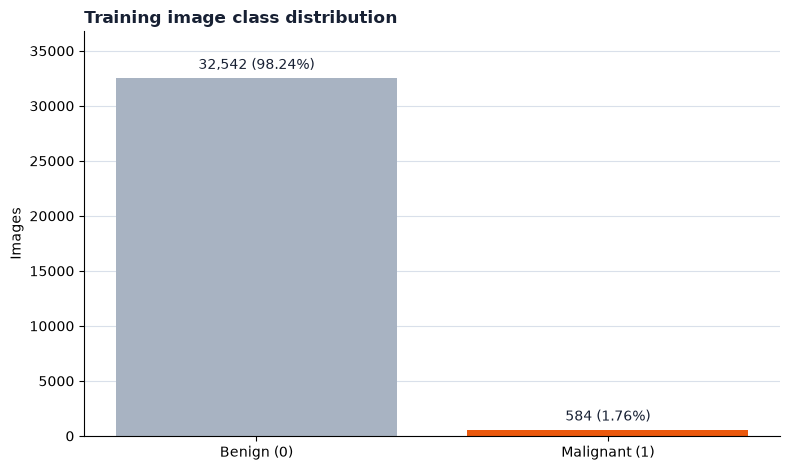

In [5]:
BLUE = "#2563EB"
ORANGE = "#EA580C"
GOLD = "#D4A72C"
INK = "#172033"
GRID = "#D9E0EA"
NEUTRAL = "#A8B3C2"

target_summary = (
    train["target"]
    .value_counts()
    .reindex([0, 1], fill_value=0)
    .rename(index={0: "Benign (0)", 1: "Malignant (1)"})
)

fig, ax = plt.subplots(figsize=(8, 4.8))
bars = ax.bar(target_summary.index, target_summary.values, color=[NEUTRAL, ORANGE])
ax.set_title("Training image class distribution", loc="left", color=INK, weight="bold")
ax.set_ylabel("Images")
ax.set_ylim(0, target_summary.max() * 1.13)
ax.grid(axis="y", color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)

for bar, count in zip(bars, target_summary.values):
    share = count / len(train)
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + target_summary.max() * 0.025,
        f"{count:,} ({share:.2%})",
        ha="center",
        color=INK,
    )

plt.tight_layout()
plt.show()


The target is severely imbalanced. Accuracy alone would be misleading; later evaluation should prioritise metrics such as ROC AUC, PR AUC, sensitivity/recall, specificity, and confusion matrices at clinically relevant thresholds.


### Number of Patients vs Image Recorded


Images per patient quantiles:
0.00      2.00
0.25      5.00
0.50     12.00
0.75     22.00
0.90     35.00
0.95     44.25
0.99     80.25
1.00    115.00


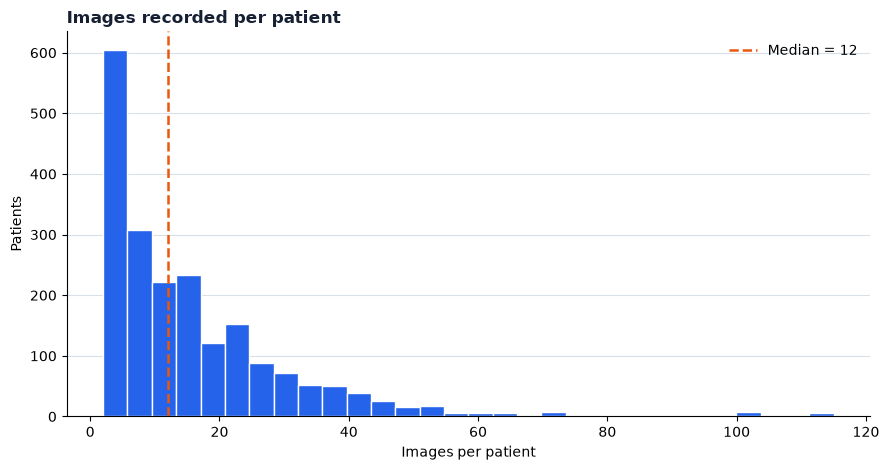

In [6]:
patient_quantiles = patient_summary["image_count"].quantile(
    [0, 0.25, 0.5, 0.75, 0.9, 0.95, 0.99, 1]
)
print("Images per patient quantiles:")
print(patient_quantiles.to_string())

fig, ax = plt.subplots(figsize=(9, 4.8))
ax.hist(patient_summary["image_count"], bins=30, color=BLUE, edgecolor="white")
ax.axvline(
    patient_summary["image_count"].median(),
    color=ORANGE,
    linestyle="--",
    linewidth=1.8,
    label=f"Median = {patient_summary['image_count'].median():.0f}",
)
ax.set_title("Images recorded per patient", loc="left", color=INK, weight="bold")
ax.set_xlabel("Images per patient")
ax.set_ylabel("Patients")
ax.grid(axis="y", color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()


Multiple images from the same patient are correlated. A row-level random split could place one patient's images in both training and validation sets, creating optimistic validation results. Use `StratifiedGroupKFold`, stratifying by `target` and grouping by `patient_id`.


### Explore metadata distributions and observed malignancy rates


In [7]:
def ordered_age_categories(values: pd.Series) -> list[str]:
    known = sorted(
        (value for value in values.dropna().unique() if value != "Unknown"),
        key=lambda value: int(value),
    )
    return [*known, "Unknown"] if "Unknown" in set(values) else known


def summarise_feature(
    frame: pd.DataFrame,
    feature: str,
    order: list[str] | None = None,
) -> pd.DataFrame:
    summary = frame.groupby(feature, dropna=False)["target"].agg(
        image_count="size",
        malignant_images="sum",
        malignancy_rate="mean",
    )
    if order is not None:
        summary = summary.reindex(order)
    else:
        summary = summary.sort_values("image_count", ascending=False)
    return summary


feature_summaries = {
    "sex": summarise_feature(train, "sex"),
    "age_approx": summarise_feature(
        train,
        "age_approx",
        ordered_age_categories(train["age_approx"]),
    ),
    "anatom_site_general_challenge": summarise_feature(
        train,
        "anatom_site_general_challenge",
    ),
}

for feature, summary in feature_summaries.items():
    print(f"\n{feature}")
    printable = summary.copy()
    printable["malignancy_rate"] = printable["malignancy_rate"].map(lambda x: f"{x:.2%}")
    print(printable.to_string())



sex
         image_count  malignant_images malignancy_rate
sex                                                   
male           17080               364           2.13%
female         15981               220           1.38%
Unknown           65                 0           0.00%

age_approx
            image_count  malignant_images malignancy_rate
age_approx                                               
0                     2                 0           0.00%
10                   17                 0           0.00%
15                  132                 2           1.52%
20                  655                 6           0.92%
25                 1544                16           1.04%
30                 2358                24           1.02%
35                 2850                25           0.88%
40                 3576                24           0.67%
45                 4466                54           1.21%
50                 4270                53           1.24%
55          

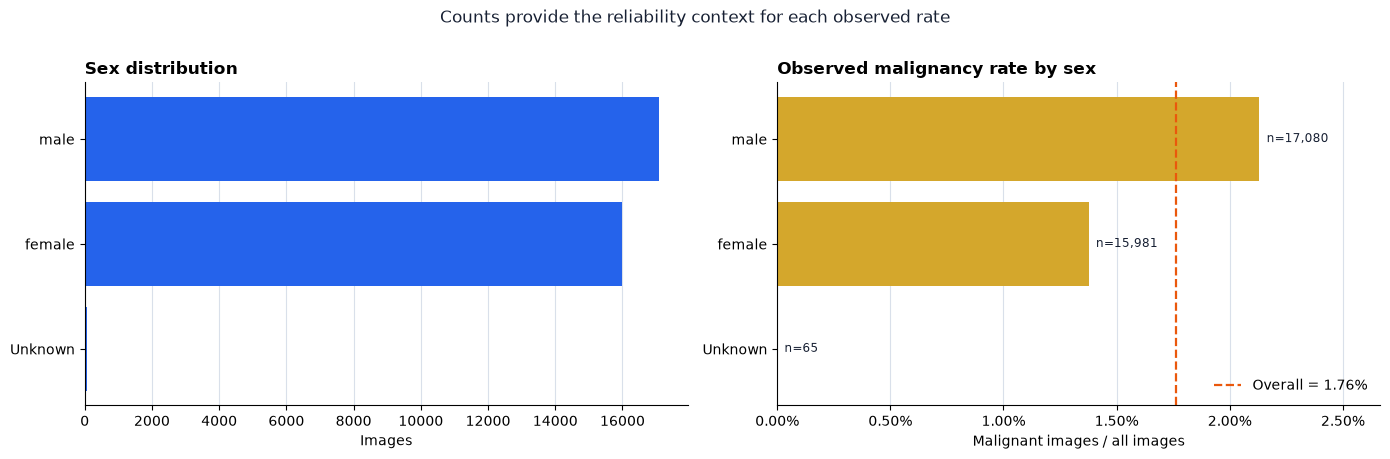

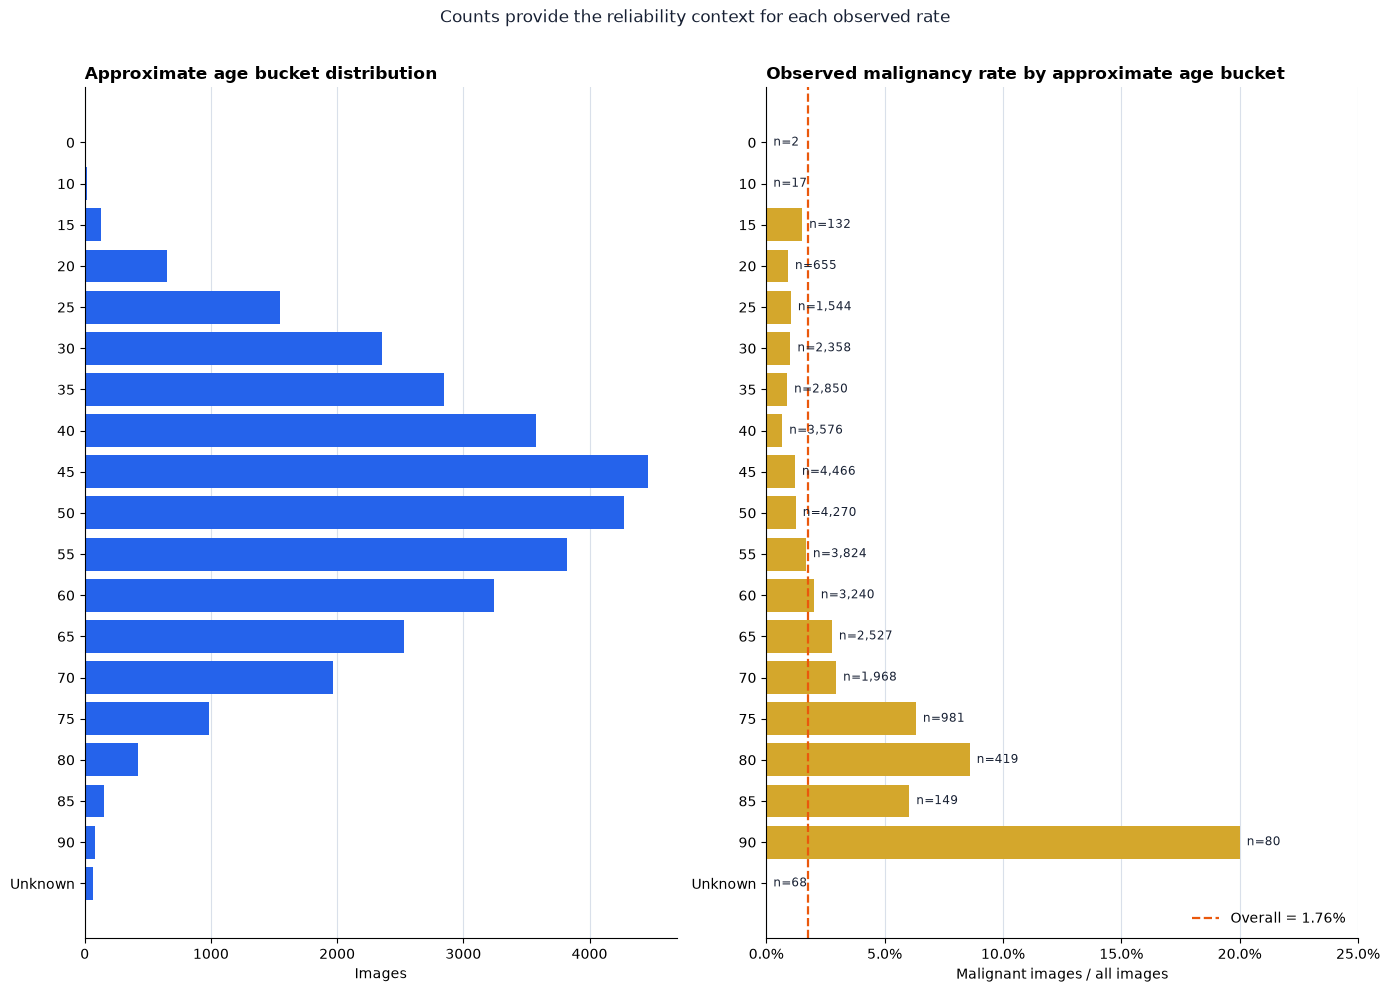

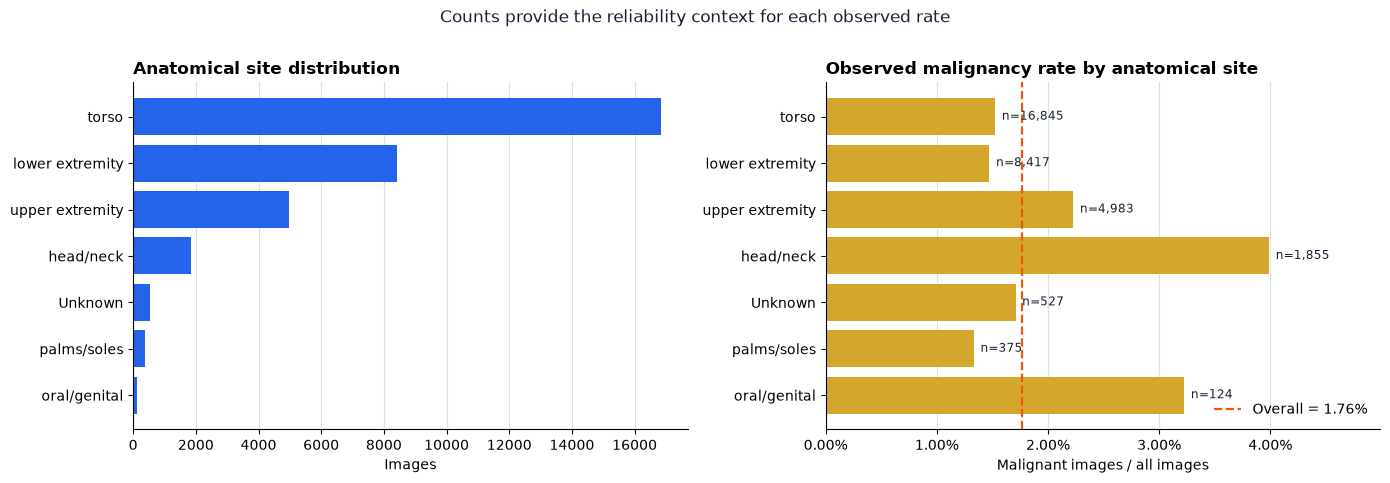

In [8]:
FEATURE_LABELS = {
    "sex": "Sex",
    "age_approx": "Approximate age bucket",
    "anatom_site_general_challenge": "Anatomical site",
}


def plot_feature_summary(feature: str, summary: pd.DataFrame) -> None:
    labels = summary.index.astype(str)
    positions = np.arange(len(summary))
    height = max(4.5, 0.42 * len(summary) + 1.8)
    fig, axes = plt.subplots(1, 2, figsize=(14, height))

    axes[0].barh(positions, summary["image_count"], color=BLUE)
    axes[0].set_yticks(positions, labels)
    axes[0].invert_yaxis()
    axes[0].set_title(f"{FEATURE_LABELS[feature]} distribution", loc="left", weight="bold")
    axes[0].set_xlabel("Images")

    axes[1].barh(positions, summary["malignancy_rate"], color=GOLD)
    axes[1].set_yticks(positions, labels)
    axes[1].invert_yaxis()
    axes[1].set_title(
        f"Observed malignancy rate by {FEATURE_LABELS[feature].lower()}",
        loc="left",
        weight="bold",
    )
    axes[1].set_xlabel("Malignant images / all images")
    axes[1].xaxis.set_major_formatter(PercentFormatter(1.0))
    axes[1].axvline(
        train["target"].mean(),
        color=ORANGE,
        linestyle="--",
        linewidth=1.6,
        label=f"Overall = {train['target'].mean():.2%}",
    )
    axes[1].legend(frameon=False, loc="lower right")

    rate_limit = max(summary["malignancy_rate"].max() * 1.25, train["target"].mean() * 1.5)
    axes[1].set_xlim(0, rate_limit)
    for position, (_, row) in enumerate(summary.iterrows()):
        axes[1].text(
            row["malignancy_rate"] + rate_limit * 0.012,
            position,
            f"n={int(row['image_count']):,}",
            va="center",
            fontsize=8.5,
            color=INK,
        )

    for ax in axes:
        ax.grid(axis="x", color=GRID, linewidth=0.8)
        ax.set_axisbelow(True)
        ax.spines[["top", "right"]].set_visible(False)

    fig.suptitle("Counts provide the reliability context for each observed rate", y=1.01, color=INK)
    plt.tight_layout()
    plt.show()


for feature, summary in feature_summaries.items():
    plot_feature_summary(feature, summary)


Rates for small categories—especially very young or old age buckets and less-common anatomical sites—are based on limited numbers of images. They should not be treated as precise estimates or causal effects.


### 7. Audit outcome-related training fields


In [9]:
diagnosis_summary = (
    train.groupby("diagnosis")["target"]
    .agg(image_count="size", malignant_images="sum", malignancy_rate="mean")
    .sort_values("image_count", ascending=False)
)
diagnosis_summary["malignancy_rate"] = diagnosis_summary["malignancy_rate"].map(
    lambda value: f"{value:.2%}"
)
print(diagnosis_summary.to_string())


                                    image_count  malignant_images malignancy_rate
diagnosis                                                                        
unknown                                   27124                 0           0.00%
nevus                                      5193                 0           0.00%
melanoma                                    584               584         100.00%
seborrheic keratosis                        135                 0           0.00%
lentigo NOS                                  44                 0           0.00%
lichenoid keratosis                          37                 0           0.00%
solar lentigo                                 7                 0           0.00%
atypical melanocytic proliferation            1                 0           0.00%
cafe-au-lait macule                           1                 0           0.00%


`diagnosis` and `benign_malignant` are useful for checking label consistency and understanding how the target was constructed. They must be excluded from the predictor matrix because they reveal the outcome and are unavailable in the competition test data.


## Takeaways

1. The cleaned metadata passes the essential completeness, uniqueness, and label-consistency checks.
2. The malignant class is rare (1.76%), so stratification and imbalance-aware evaluation are essential.
3. Patient-level grouping is mandatory because images are not independent observations.
4. Age and anatomical-site patterns are worth modelling, but subgroup rates for small categories require caution.
5. The next data-preparation step should create folds from `train_clean.csv` using `StratifiedGroupKFold(target, groups=patient_id)`.
